# COSC 4V88 Project 5 – Part A, Step 1: Data and baseline models

**Owner:** Shuo Gao (Part A)

This notebook prepares everything Parts B and C need to start:

1. Download and clean the UCI Default of Credit Card Clients dataset.
2. Make one fixed, stratified train / validation / test split (60/20/20, seed 42).
3. Train the interpretable baseline (Logistic Regression) and the flexible model (XGBoost) under the same conditions.
4. Choose each model's decision threshold on the **validation** set only.
5. Report test-set results with counts and 95% bootstrap confidence intervals, plus a first subgroup check and a proxy check.
6. Save the split, models, predictions and settings into `part_a_outputs.zip`.

**Rules for everyone using these outputs**

- Use the saved split files. Do not re-split the data.
- Use the test set only for final numbers. Tune and choose thresholds on validation.
- Every client keeps its original `ID`, so we can all refer to the same client in the demo.

Run with **Runtime → Run all**. It takes a few minutes.

In [1]:
# Install packages that Colab may not have (xlrd reads the original .xls file)
!pip -q install xgboost xlrd

In [2]:
import json, os, platform, random, urllib.request, zipfile, shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score,
                             accuracy_score, brier_score_loss, confusion_matrix)
from sklearn.calibration import calibration_curve

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUT = "part_a_outputs"
for sub in ["data", "models", "results", "figures"]:
    os.makedirs(f"{OUT}/{sub}", exist_ok=True)

VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "xgboost": xgb.__version__,
}
print(VERSIONS)

{'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1'}


## 1. Load the dataset

Source: UCI Machine Learning Repository, *Default of Credit Card Clients* (dataset id 350).
30,000 credit card clients in Taiwan (April–September 2005); the target is default on the next month's payment.

If you upload the UCI zip (`default+of+credit+card+clients.zip`) or the `.xls` file to Colab's file panel first, the cell uses it. Otherwise it downloads the zip from UCI.

In [3]:
import glob
UCI_URL = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"

xls_files = glob.glob("*.xls")
if not xls_files:
    local_zips = glob.glob("*credit*card*.zip")          # a zip you uploaded to Colab yourself
    zip_path = local_zips[0] if local_zips else "uci_350.zip"
    if not local_zips:
        urllib.request.urlretrieve(UCI_URL, zip_path)   # otherwise download it from UCI
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(".")
    xls_files = glob.glob("*.xls") + glob.glob("**/*.xls", recursive=True)
RAW_XLS = xls_files[0]
print("Using", RAW_XLS)

# The first row of the file holds X1..X23 / Y codes; the second row holds the real column names
raw = pd.read_excel(RAW_XLS, header=1)
print(raw.shape)
raw.head()

Using default of credit card clients.xls
(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Clean the data

Documented changes (also saved to `results/cleaning_log.json`):

- Rename `PAY_0` to `PAY_1` so the six repayment columns line up with `BILL_AMT1–6` and `PAY_AMT1–6`.
- Rename the target to `default`.
- `EDUCATION` codes 0, 5 and 6 are not in the dataset documentation, so they are merged into 4 ("others").
- `MARRIAGE` code 0 is not documented, so it is merged into 3 ("others").
- `PAY_1–6` values −2 and 0 are also undocumented. They are kept as they are and listed as a limitation.

In [4]:
df = raw.copy().rename(columns={"PAY_0": "PAY_1", "default payment next month": "default"})

cleaning_log = {
    "rows_raw": int(len(df)),
    "missing_values": int(df.isna().sum().sum()),
    "duplicate_IDs": int(df["ID"].duplicated().sum()),
    "EDUCATION_before": {int(k): int(v) for k, v in df["EDUCATION"].value_counts().sort_index().items()},
    "MARRIAGE_before": {int(k): int(v) for k, v in df["MARRIAGE"].value_counts().sort_index().items()},
}

df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

cleaning_log["EDUCATION_after"] = {int(k): int(v) for k, v in df["EDUCATION"].value_counts().sort_index().items()}
cleaning_log["MARRIAGE_after"] = {int(k): int(v) for k, v in df["MARRIAGE"].value_counts().sort_index().items()}
cleaning_log["default_rate"] = round(float(df["default"].mean()), 4)
cleaning_log["notes"] = [
    "PAY_0 renamed to PAY_1; target renamed to default",
    "EDUCATION 0/5/6 merged into 4 (others); MARRIAGE 0 merged into 3 (others)",
    "PAY_1-6 values -2 and 0 are undocumented and kept unchanged (limitation)",
]
print(json.dumps(cleaning_log, indent=2))

{
  "rows_raw": 30000,
  "missing_values": 0,
  "duplicate_IDs": 0,
  "EDUCATION_before": {
    "0": 14,
    "1": 10585,
    "2": 14030,
    "3": 4917,
    "4": 123,
    "5": 280,
    "6": 51
  },
  "MARRIAGE_before": {
    "0": 54,
    "1": 13659,
    "2": 15964,
    "3": 323
  },
  "EDUCATION_after": {
    "1": 10585,
    "2": 14030,
    "3": 4917,
    "4": 468
  },
  "MARRIAGE_after": {
    "1": 13659,
    "2": 15964,
    "3": 377
  },
  "default_rate": 0.2212,
  "notes": [
    "PAY_0 renamed to PAY_1; target renamed to default",
    "EDUCATION 0/5/6 merged into 4 (others); MARRIAGE 0 merged into 3 (others)",
    "PAY_1-6 values -2 and 0 are undocumented and kept unchanged (limitation)"
  ]
}


## 3. Features

`SEX`, `EDUCATION`, `MARRIAGE` and `AGE` are sensitive attributes. They are **always kept in the saved files** so we can audit results by group.

**Group decision: the models do not use them as inputs.** This is closer to how a lender should operate and easier to justify ethically. Removing them does not guarantee fairness, because other features can act as proxies (see the proxy check in Section 10), so we still audit every result by group.

In [5]:
USE_SENSITIVE_AS_FEATURES = False   # group decision: sensitive attributes are kept for auditing only

TARGET = "default"
SENSITIVE = ["SEX", "EDUCATION", "MARRIAGE", "AGE"]
ALL_FEATURES = [c for c in df.columns if c not in ["ID", TARGET]]
FEATURES = ALL_FEATURES if USE_SENSITIVE_AS_FEATURES else [c for c in ALL_FEATURES if c not in SENSITIVE]
print(len(FEATURES), "features:", FEATURES)

19 features: ['LIMIT_BAL', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


## 4. Fixed train / validation / test split (60/20/20)

Stratified on the target so each part has the same default rate. The seed is fixed, so the split is identical every time.

In [6]:
train_df, temp_df = train_test_split(df, test_size=0.4, stratify=df[TARGET], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df[TARGET], random_state=SEED)

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    part.to_csv(f"{OUT}/data/{name}.csv", index=False)
    print(f"{name:5s} n={len(part):5d}  defaults={int(part[TARGET].sum()):4d}  rate={part[TARGET].mean():.3f}")

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_val, y_val = val_df[FEATURES], val_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

train n=18000  defaults=3982  rate=0.221
val   n= 6000  defaults=1327  rate=0.221
test  n= 6000  defaults=1327  rate=0.221


## 5. Train the two models

Both models see exactly the same features, training rows and evaluation rules.

- **Logistic Regression** (interpretable baseline): features are standardised inside the pipeline, so its coefficients are comparable.
- **XGBoost** (flexible model): fixed, moderate settings. The validation set is used only for early stopping.

In [7]:
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=2000, random_state=SEED)),
])
lr.fit(X_train, y_train)

XGB_PARAMS = dict(
    n_estimators=1000, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
    min_child_weight=5, reg_lambda=1.0, eval_metric="auc", early_stopping_rounds=50,
    random_state=SEED, n_jobs=-1,
)
xgb_model = xgb.XGBClassifier(**XGB_PARAMS)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print("XGBoost best iteration:", xgb_model.best_iteration)

models = {"LogisticRegression": lr, "XGBoost": xgb_model}

XGBoost best iteration: 143


## 6. Choose decision thresholds on the validation set

Only about 22% of clients default, so the default 0.5 cut-off misses many defaulters. For each model we pick the threshold that maximises F1 on the **validation** set and then freeze it. Part C uses these thresholds to find "borderline" predictions.

In [8]:
def best_f1_threshold(y_true, proba):
    grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
    scores = [f1_score(y_true, (proba >= t).astype(int), zero_division=0) for t in grid]
    i = int(np.argmax(scores))
    return float(grid[i]), float(scores[i])

THRESHOLDS = {}
for name, m in models.items():
    t, f = best_f1_threshold(y_val, m.predict_proba(X_val)[:, 1])
    THRESHOLDS[name] = t
    print(f"{name}: threshold={t:.2f} (validation F1={f:.3f})")

LogisticRegression: threshold=0.25 (validation F1=0.507)
XGBoost: threshold=0.26 (validation F1=0.533)


## 7. Test-set results with counts and 95% bootstrap confidence intervals

Each metric is reported with its 95% interval from 1,000 bootstrap resamples of the test set, together with the confusion-matrix counts behind it.

In [9]:
def metrics_at(y_true, proba, t):
    pred = (proba >= t).astype(int)
    return {
        "AUC": roc_auc_score(y_true, proba),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Recall (defaulters)": recall_score(y_true, pred, zero_division=0),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, pred),
        "Brier score": brier_score_loss(y_true, proba),
    }

def bootstrap_ci(y_true, proba, t, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true); proba = np.asarray(proba)
    draws = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].min() == y_true[idx].max():
            continue
        draws.append(metrics_at(y_true[idx], proba[idx], t))
    d = pd.DataFrame(draws)
    return d.quantile(0.025), d.quantile(0.975)

rows = []
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    t = THRESHOLDS[name]
    point = metrics_at(y_test, proba, t)
    lo, hi = bootstrap_ci(y_test, proba, t)
    tn, fp, fn, tp = confusion_matrix(y_test, (proba >= t).astype(int)).ravel()
    for k, v in point.items():
        rows.append({"model": name, "metric": k, "value": round(v, 4),
                     "ci_low": round(lo[k], 4), "ci_high": round(hi[k], 4)})
    print(f"{name} @ t={t:.2f}: TP={tp} FP={fp} FN={fn} TN={tn} (n={len(y_test)}, defaulters={int(y_test.sum())})")

results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/results/test_metrics.csv", index=False)
results.pivot(index="metric", columns="model", values="value")

LogisticRegression @ t=0.25: TP=712 FP=713 FN=615 TN=3960 (n=6000, defaulters=1327)
XGBoost @ t=0.26: TP=776 FP=688 FN=551 TN=3985 (n=6000, defaulters=1327)


model,LogisticRegression,XGBoost
metric,,
AUC,0.7214,0.7861
Accuracy,0.7787,0.7935
Brier score,0.1444,0.1330
F1,0.5174,0.5561
Precision,0.4996,0.5301
Recall (defaulters),0.5365,0.5848


## 8. Calibration

A model is well calibrated if, among clients given a predicted risk of about 0.3, about 30% actually default. Good ranking (AUC) does not guarantee this.

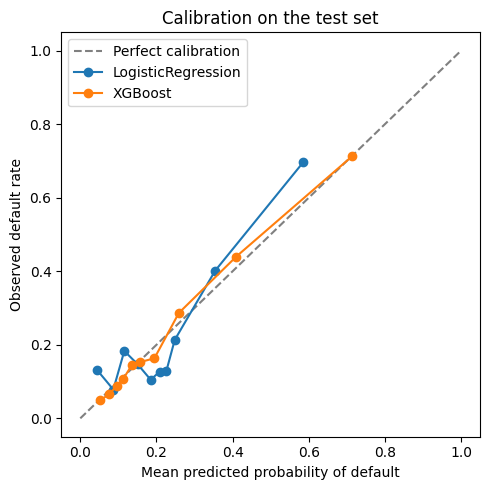

In [10]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
for name, m in models.items():
    frac_pos, mean_pred = calibration_curve(y_test, m.predict_proba(X_test)[:, 1], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.set_xlabel("Mean predicted probability of default")
ax.set_ylabel("Observed default rate")
ax.set_title("Calibration on the test set")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/figures/calibration_test.png", dpi=200)
plt.show()

## 9. First subgroup check

Recall on defaulters (true positive rate) by group, with group sizes. The equal opportunity gap is the largest minus the smallest group recall. Groups with fewer than 30 defaulters in the test set are marked as too small to compare reliably.

In [11]:
eval_df = test_df.copy()
eval_df["AGE_BAND"] = pd.cut(eval_df["AGE"], bins=[0, 29, 39, 49, 200], labels=["<30", "30-39", "40-49", "50+"])
eval_df["SEX_LABEL"] = eval_df["SEX"].map({1: "male", 2: "female"})
eval_df["EDU_LABEL"] = eval_df["EDUCATION"].map({1: "graduate school", 2: "university", 3: "high school", 4: "others"})

sub_rows = []
for name, m in models.items():
    eval_df["pred"] = (m.predict_proba(X_test)[:, 1] >= THRESHOLDS[name]).astype(int)
    for col in ["SEX_LABEL", "AGE_BAND", "EDU_LABEL"]:
        for g, part in eval_df.groupby(col, observed=True):
            pos = part[part[TARGET] == 1]
            sub_rows.append({
                "model": name, "attribute": col.replace("_LABEL", "").replace("_BAND", ""), "group": str(g),
                "n": len(part), "defaulters": len(pos),
                "recall": round(pos["pred"].mean(), 4) if len(pos) else np.nan,
                "too_small": len(pos) < 30,
            })
subgroups = pd.DataFrame(sub_rows)
subgroups.to_csv(f"{OUT}/results/subgroup_recall.csv", index=False)

gaps = (subgroups[~subgroups["too_small"]]
        .groupby(["model", "attribute"])["recall"].agg(lambda s: round(s.max() - s.min(), 4))
        .rename("equal_opportunity_gap").reset_index())
display(subgroups)
display(gaps)

,model,attribute,group,n,defaulters,recall,too_small
0,LogisticRegression,SEX,female,3628,755,0.5536,False
1,LogisticRegression,SEX,male,2372,572,0.5140,False
2,LogisticRegression,AGE,<30,1926,421,0.5986,False
3,LogisticRegression,AGE,30-39,2206,439,0.4875,False
4,LogisticRegression,AGE,40-49,1296,318,0.5126,False
5,LogisticRegression,AGE,50+,572,149,0.5570,False
6,LogisticRegression,EDU,graduate school,2141,412,0.4709,False
7,LogisticRegression,EDU,high school,989,262,0.5496,False
8,LogisticRegression,EDU,others,95,7,0.1429,True
9,LogisticRegression,EDU,university,2775,646,0.5774,False


,model,attribute,equal_opportunity_gap
0,LogisticRegression,AGE,0.1111
1,LogisticRegression,EDU,0.1065
2,LogisticRegression,SEX,0.0396
3,XGBoost,AGE,0.0946
4,XGBoost,EDU,0.0032
5,XGBoost,SEX,0.0138


## 10. Proxy check: can the remaining features reveal the sensitive attributes?

The models no longer see sex, age or education, but other features may still carry that information. Here a small model tries to predict each sensitive attribute from the model's own input features. An AUC near 0.5 means the features reveal little; the closer to 1, the stronger the proxy. We also list the features that are most correlated with each attribute.

In [12]:
from sklearn.ensemble import RandomForestClassifier

proxy_targets = {
    "SEX (female)": (df["SEX"] == 2).astype(int),
    "AGE (40 or older)": (df["AGE"] >= 40).astype(int),
    "EDUCATION (graduate school)": (df["EDUCATION"] == 1).astype(int),
    "MARRIAGE (married)": (df["MARRIAGE"] == 1).astype(int),
}
tr_idx, te_idx = train_df.index, test_df.index
proxy_rows, corr_rows = [], []
for label, target in proxy_targets.items():
    rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=SEED, n_jobs=-1)
    rf.fit(df.loc[tr_idx, FEATURES], target.loc[tr_idx])
    auc = roc_auc_score(target.loc[te_idx], rf.predict_proba(df.loc[te_idx, FEATURES])[:, 1])
    proxy_rows.append({"sensitive attribute": label, "proxy AUC (test)": round(auc, 3)})
    corr = df[FEATURES].corrwith(target).abs().sort_values(ascending=False).head(3)
    for feat, val in corr.items():
        corr_rows.append({"sensitive attribute": label, "feature": feat, "abs correlation": round(val, 3)})

proxy_auc = pd.DataFrame(proxy_rows)
proxy_corr = pd.DataFrame(corr_rows)
proxy_auc.to_csv(f"{OUT}/results/proxy_check_auc.csv", index=False)
proxy_corr.to_csv(f"{OUT}/results/proxy_check_top_features.csv", index=False)
display(proxy_auc)
display(proxy_corr)

,sensitive attribute,proxy AUC (test)
0,SEX (female),0.604
1,AGE (40 or older),0.571
2,EDUCATION (graduate school),0.687
3,MARRIAGE (married),0.562


,sensitive attribute,feature,abs correlation
0,SEX (female),PAY_2,0.071
1,SEX (female),PAY_3,0.066
2,SEX (female),PAY_4,0.060
3,AGE (40 or older),LIMIT_BAL,0.047
4,AGE (40 or older),BILL_AMT1,0.027
5,AGE (40 or older),BILL_AMT2,0.026
6,EDUCATION (graduate school),LIMIT_BAL,0.259
7,EDUCATION (graduate school),PAY_2,0.169
8,EDUCATION (graduate school),PAY_3,0.160
9,MARRIAGE (married),LIMIT_BAL,0.104


## 11. Save everything for Parts B and C

`part_a_outputs.zip` contains:

- `data/train.csv`, `val.csv`, `test.csv`: the fixed split (all columns, including `ID` and sensitive attributes)
- `models/logistic_regression.joblib`, `models/xgboost.joblib`: the trained models
- `results/predictions_val.csv`, `predictions_test.csv`: each client's predicted probability and decision from both models
- `results/config.json`: seed, features, thresholds, model settings, package versions and cleaning log
- `results/test_metrics.csv`, `subgroup_recall.csv`, `proxy_check_auc.csv`, `proxy_check_top_features.csv`, `figures/calibration_test.png`

To load a model: `model = joblib.load("models/xgboost.joblib")`, then `model.predict_proba(X[FEATURES])[:, 1]` using the feature list in `config.json`.

In [13]:
joblib.dump(lr, f"{OUT}/models/logistic_regression.joblib")
joblib.dump(xgb_model, f"{OUT}/models/xgboost.joblib")

for split_name, part in [("val", val_df), ("test", test_df)]:
    preds = part[["ID", TARGET]].copy()
    for name, m in models.items():
        p = m.predict_proba(part[FEATURES])[:, 1]
        preds[f"proba_{name}"] = np.round(p, 6)
        preds[f"pred_{name}"] = (p >= THRESHOLDS[name]).astype(int)
    preds.to_csv(f"{OUT}/results/predictions_{split_name}.csv", index=False)

config = {
    "seed": SEED,
    "split": {"train": 0.6, "val": 0.2, "test": 0.2, "stratified_on": TARGET},
    "target": TARGET,
    "features": FEATURES,
    "use_sensitive_as_features": USE_SENSITIVE_AS_FEATURES,
    "sensitive_attributes": SENSITIVE,
    "thresholds_chosen_on_validation": THRESHOLDS,
    "logistic_regression": {"scaler": "StandardScaler", "max_iter": 2000},
    "xgboost": {**{k: v for k, v in XGB_PARAMS.items()}, "best_iteration": int(xgb_model.best_iteration)},
    "versions": VERSIONS,
    "cleaning_log": cleaning_log,
}
with open(f"{OUT}/results/config.json", "w") as f:
    json.dump(config, f, indent=2)
with open(f"{OUT}/results/cleaning_log.json", "w") as f:
    json.dump(cleaning_log, f, indent=2)

shutil.make_archive(OUT, "zip", OUT)
print("Saved", OUT + ".zip")

try:
    from google.colab import files
    files.download(OUT + ".zip")
except ImportError:
    pass

Saved part_a_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>